# 9. The rest of the route: hardening, tempering and stress relieving

Versions 1-2 modelled furnace cooling and air cooling. This notebook adds the other three classic treatments:
**hardening** (a quench in oil, water or brine), **tempering** and **stress relieving**. The data are 324
quenched-and-tempered bars of 28 AISI grades from the open Birbilis et al. (2025) database, each with the quench
medium, the austenitising and tempering temperatures and the bar size (13, 25, 50 or 100 mm) written out.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3g}")
R = ROOT / "results"; FIG = ROOT / "figures"
def fig(name, width=1000):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

In [2]:
pd.read_csv(R / "s09_qt_dataset_summary.csv").pivot_table(index="section_mm", columns="quench_medium", values="bars")

quench_medium,oil,water
section_mm,,
13,51,18
13.7,2,NaN
14,NaN,3
25,67,21
50,59,21
75,2,NaN
100,59,21


## Hardening: the quench heat flow
Radial conduction in the bar with Grossmann's severity of quench; checked against the exact Bessel solution
(tests/test_quench.py). Right: the model's ideal critical diameter against Grossmann's D_I from the ASTM A255
factors, a check that uses none of our data.

In [3]:
pd.read_csv(R / "s09_quench_rates.csv").pivot_table(index="D_mm", columns=["medium", "r_over_R"], values="rate700_K_s").round(1)

medium   ideal                oil           water          
r_over_R  0    0.5      0.75 0    0.5  0.75  0    0.5  0.75
D_mm                                                       
13         700  968 2.96e+03 29.3 28.8 28.3  94.6 91.2 92.4
25         189  262      800   15 14.6 14.2  43.8 42.3 49.5
50        47.3 65.4      200  7.1  6.8    7  17.5 17.5   25
100       11.8 16.4       50    3    3  3.6   6.3  6.7 11.5

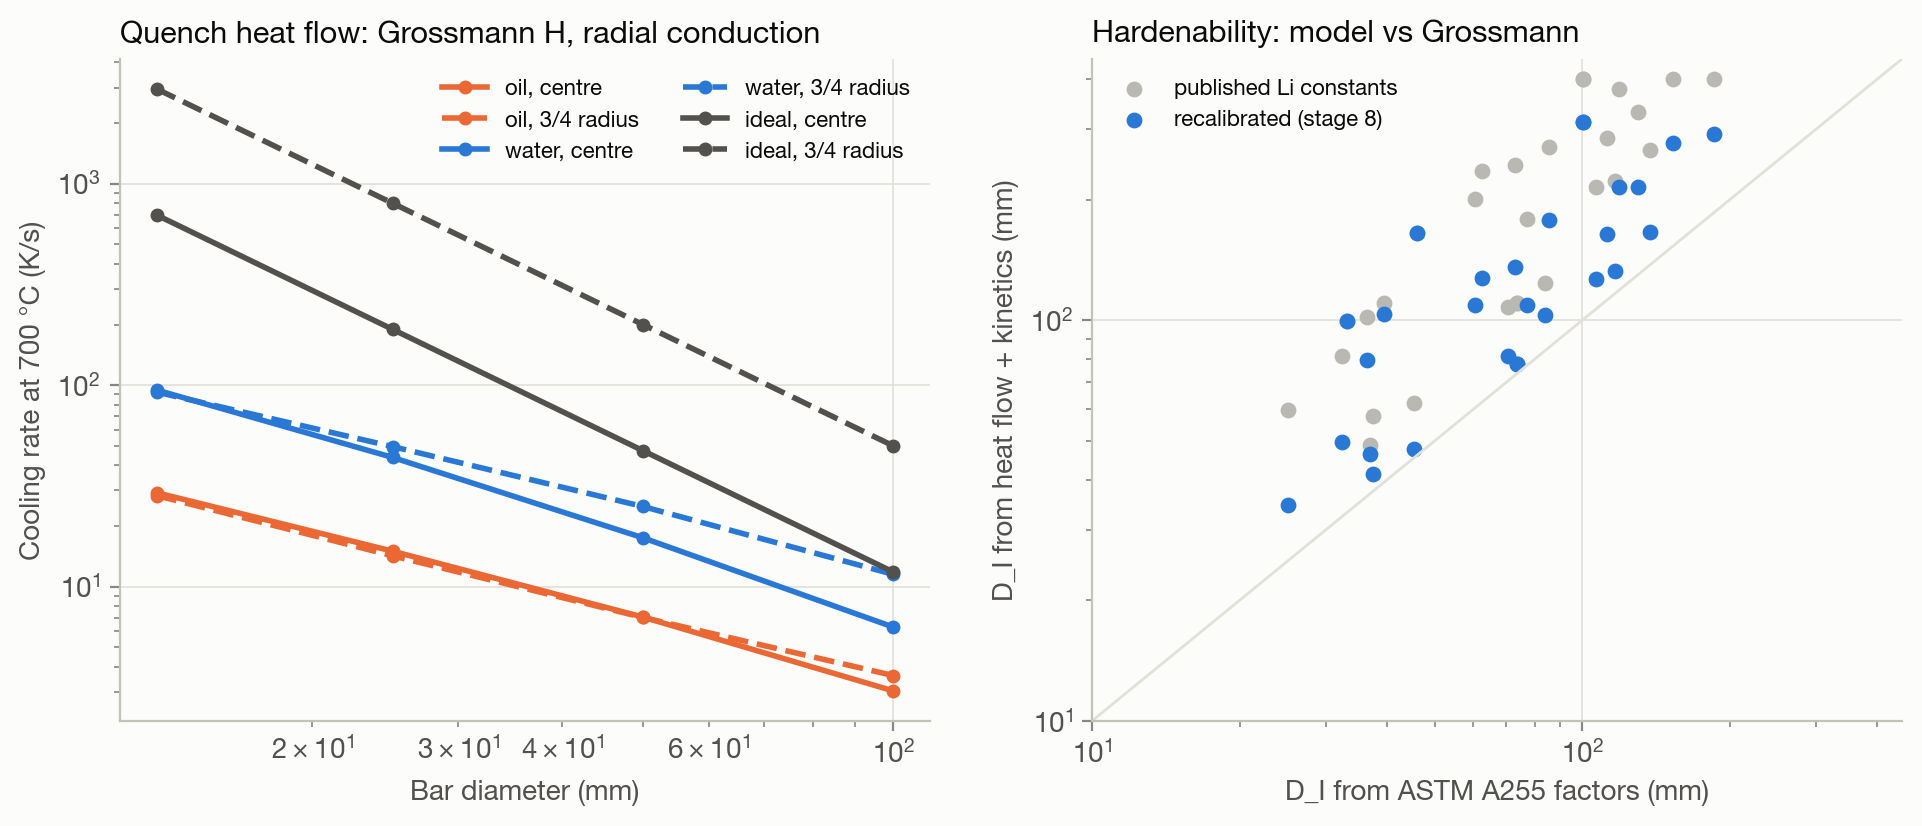

In [4]:
fig("fig31_quench_and_hardenability", 1000)

In [5]:
h = pd.read_csv(R / "s09_hardenability_check.csv")
h.assign(ratio_recalibrated=h.DI_model_calibrated_mm / h.DI_A255_mm, ratio_published=h.DI_model_published_mm / h.DI_A255_mm).round(2)

,grade,C,Mn,Cr,Ni,Mo,DI_A255_mm,DI_model_calibrated_mm,DI_model_published_mm,ratio_recalibrated,ratio_published
0,4027,0.27,0.8,0.1,0.1,0.25,37.4,41.4,57.8,1.11,1.54
1,4130,0.3,0.5,0.98,0.1,0.2,70.6,81.6,108,1.16,1.53
2,4140,0.4,0.88,0.98,0.1,0.2,138,166,267,1.21,1.94
3,4150,0.5,0.88,0.98,0.1,0.2,153,278,400,1.82,2.61
4,4340,0.4,0.73,0.8,1.78,0.25,186,293,400,1.58,2.16
5,4427,0.26,0.8,0.1,0.1,0.4,45.5,47.8,62.1,1.05,1.37
6,4422,0.22,0.75,0.1,0.1,0.4,36.9,46.5,48.9,1.26,1.33
7,5140,0.4,0.8,0.8,0.1,0.03,77.1,109,179,1.41,2.32
8,5150,0.5,0.8,0.8,0.1,0.03,85.8,178,270,2.08,3.15
9,5160,0.6,0.88,0.8,0.1,0.03,100,313,400,3.12,3.98


## Tempering: one master curve
P = T(20 + log t). The constants were fitted on the bars, with a grade bootstrap.

In [6]:
pd.read_csv(R / "s09_tempering_constants.csv")

,constant,prior_mean,prior_sd,fitted,bootstrap_sd,at_bound
0,p0,1.45e+04,2e+03,1.14e+04,480,False
1,p_Mn,300,400,-75.1,522,False
2,p_Si,1e+03,700,1.62e+03,212,False
3,p_Cr,500,500,1.04e+03,238,False
4,p_Mo,1.5e+03,1.5e+03,8.09e+03,948,False
5,p_V,3e+03,2e+03,4.18e+03,1.03e+03,False
6,logW,7.82,0.5,8.29,0.184,False
7,s0,120,40,72.5,18,False
8,s_C,150,100,89.7,54.8,False
9,a_Mo,60,80,62.1,25.5,False


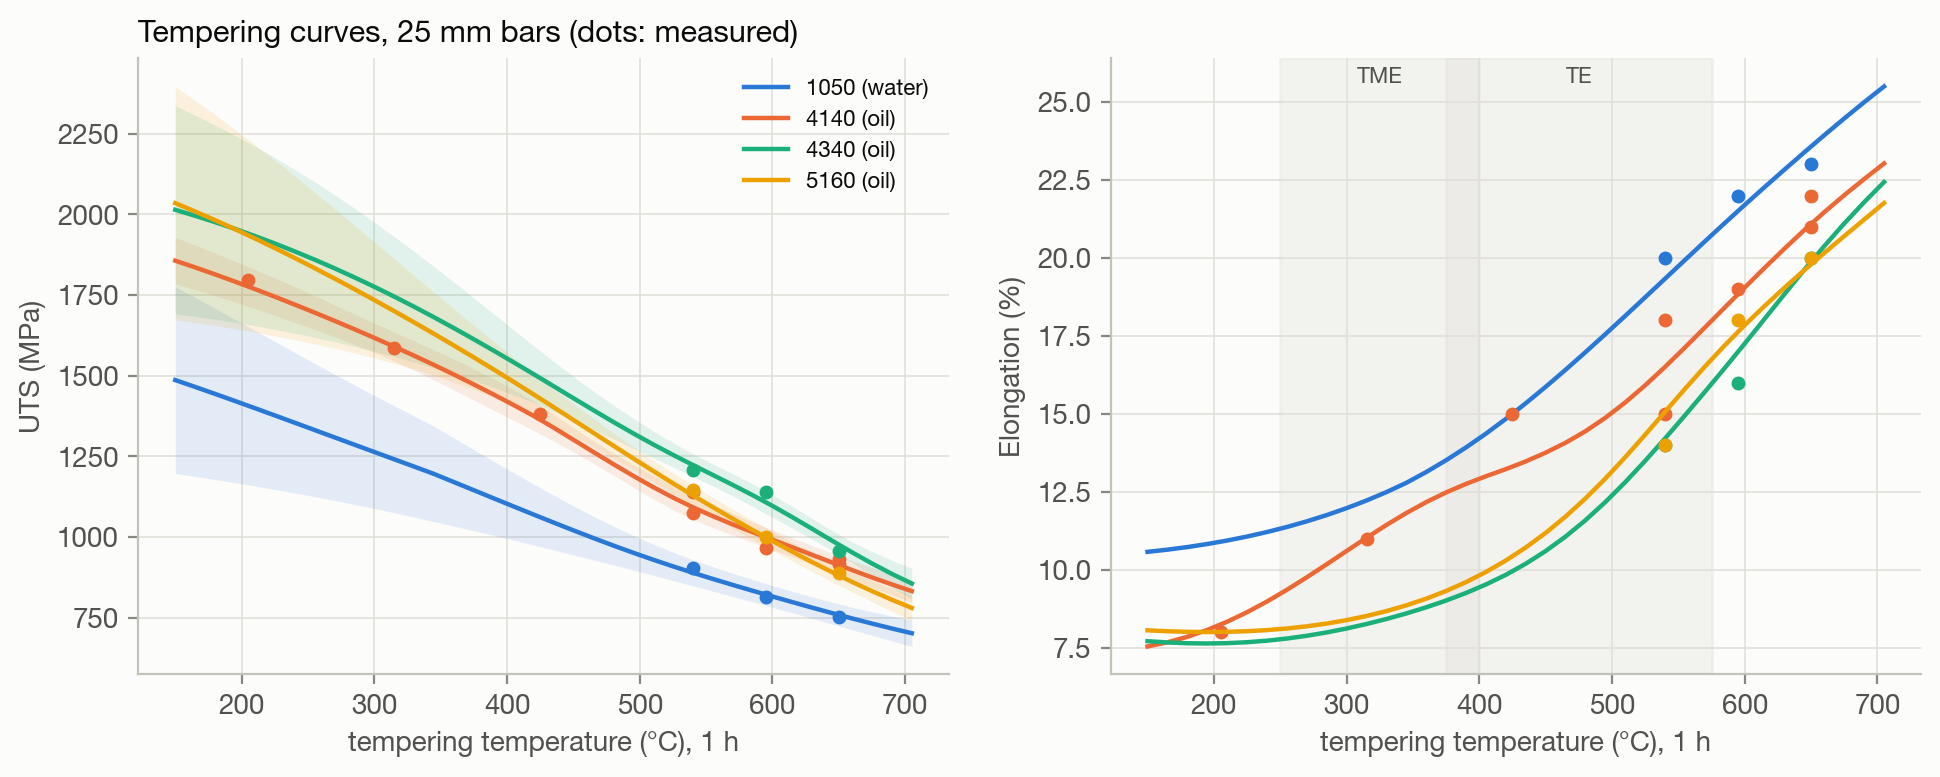

In [7]:
fig("fig35_tempering_curves", 1000)

## The model ladder (leave one grade out) and the mass effect

In [8]:
b = pd.read_csv(R / "s09_qt_benchmark.csv"); b.pivot_table(index="model", columns="target", values="RMSE").round(1)

target,El_pct,UTS_MPa,YS_MPa
model,,,
qt_anchored,2,85.9,97.5
qt_ensemble,1.7,74.6,84.7
qt_gbm,2.4,112,92.2
qt_gp,2.2,90.6,109
qt_greybox,2.6,99.5,129
qt_physics,4.5,247,268


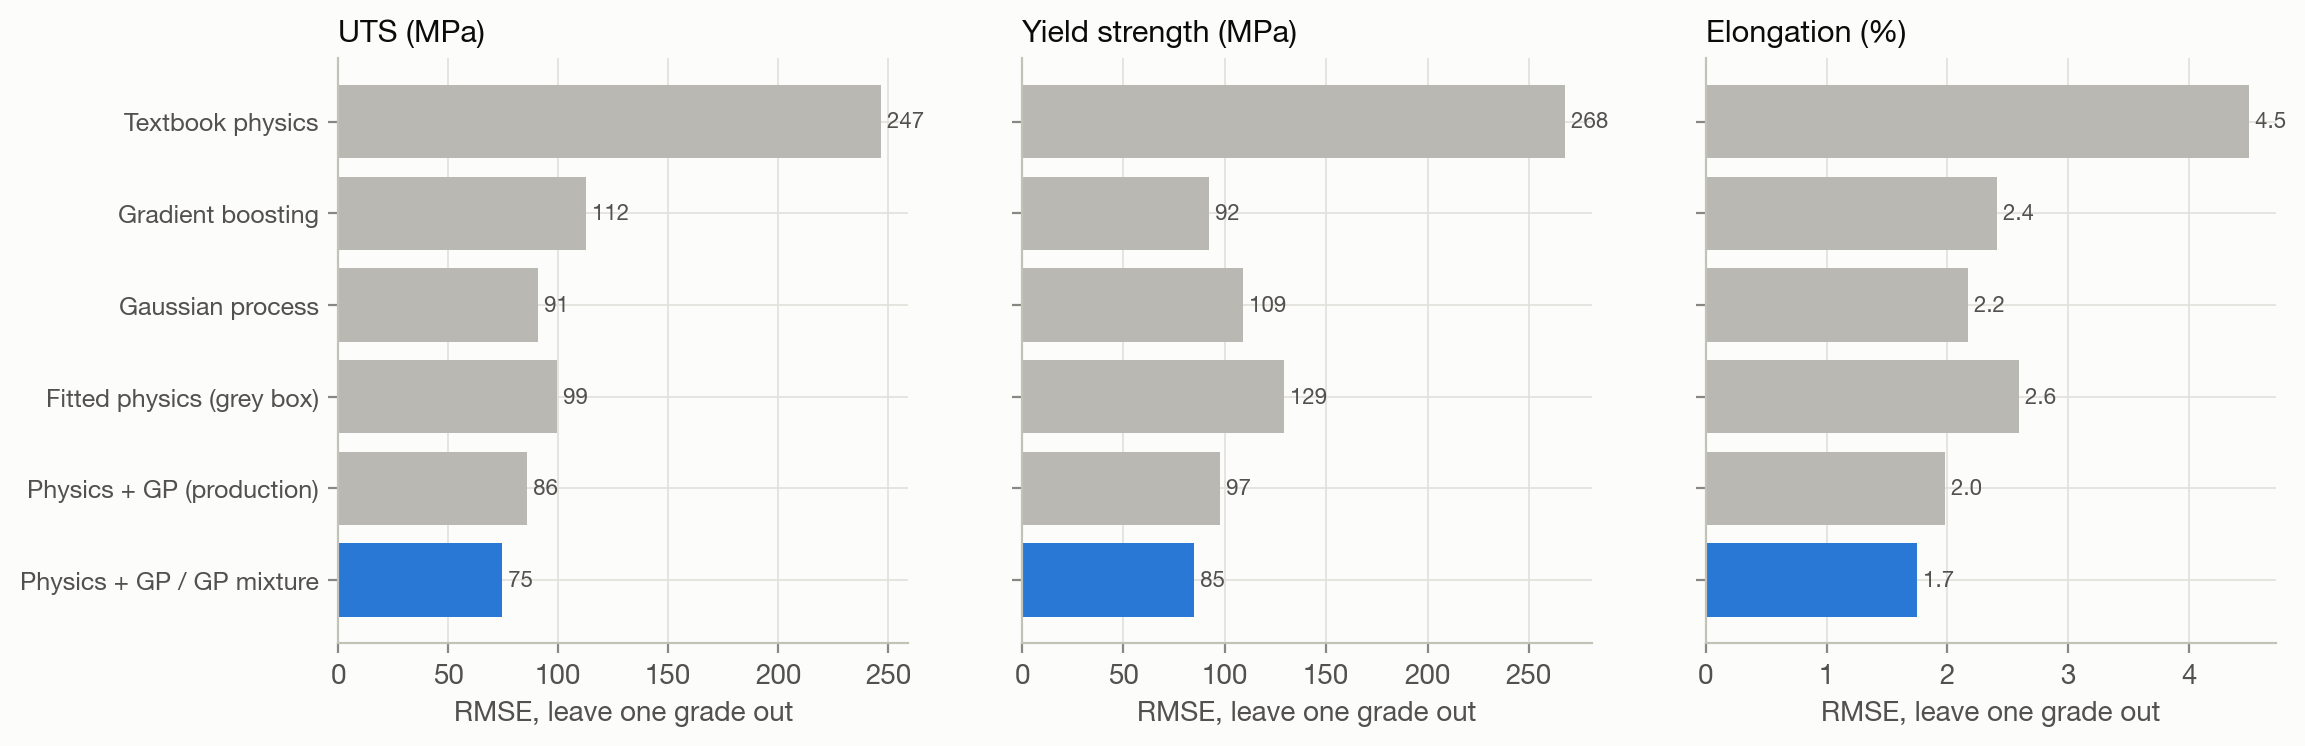

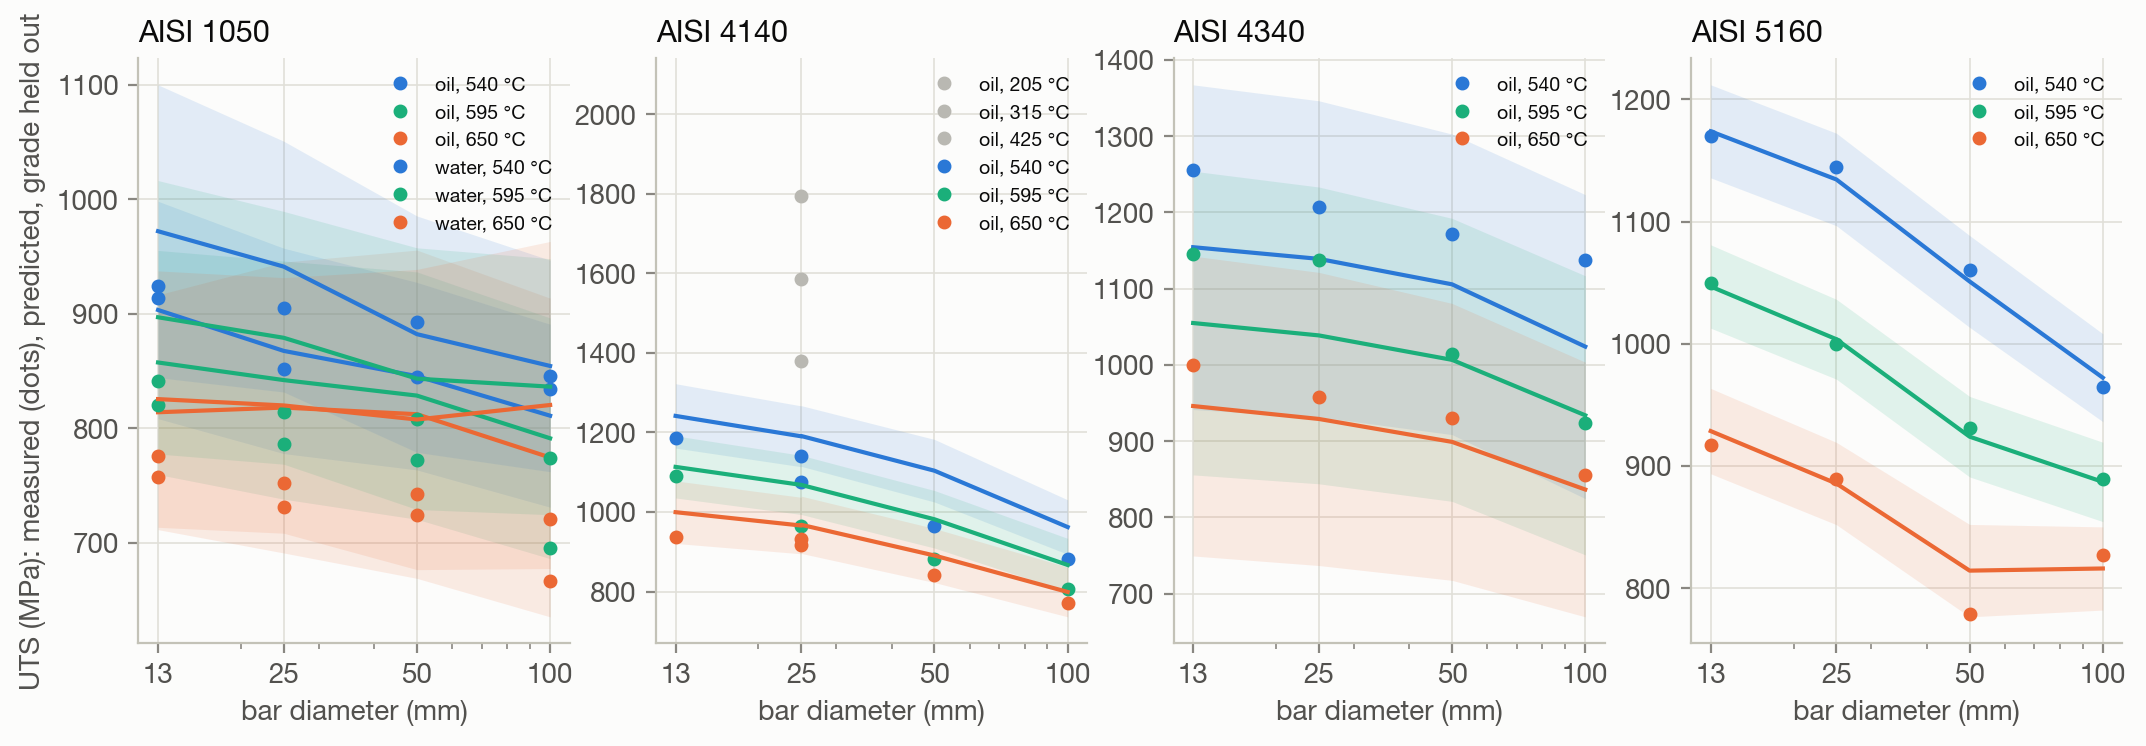

In [9]:
fig("fig32_qt_model_ladder", 1000); fig("fig34_qt_mass_effect", 1000)

In [10]:
pd.read_csv(R / "s09_qt_kinetics_check.csv").round(1)

,kinetics,model,UTS_RMSE,mean_f_martensite,mean_f_bainite,bias_13mm,bias_25mm,bias_50mm,bias_100mm
0,recalibrated (production),qt_greybox,99.5,0.4,0.3,-52.9,-45.8,-9,32
1,recalibrated (production),qt_anchored,85.9,0.4,0.3,-1.3,-1.2,-7.7,-0.6
2,published Li et al.,qt_greybox,96.3,0.6,0.2,-51.9,-40.2,-3.1,34.8
3,published Li et al.,qt_anchored,92.9,0.6,0.2,5.7,3.9,-3.3,5


## The five classic treatments, side by side
Annealing, normalising, hardening, hardening + tempering and stress relieving of six grades as 25 mm bars.

In [11]:
ft = pd.read_csv(R / "s09_five_treatments.csv")
ft[["grade", "treatment", "medium", "microstructure", "UTS_MPa_pred", "UTS_MPa_lo90", "UTS_MPa_hi90", "El_pct_pred", "HV"]].round(0)

,grade,treatment,medium,microstructure,UTS_MPa_pred,UTS_MPa_lo90,UTS_MPa_hi90,El_pct_pred,HV
0,1020,anneal,furnace,ferrite 75% + coarse pearlite 25%,399,360,437,36,120
1,1020,normalise,still air,ferrite 75% + fine pearlite 25%,442,403,480,36,140
2,1020,harden,water,ferrite 54% + pearlite 46%,NaN,NaN,NaN,NaN,155
3,1020,quench_temper,water,ferrite 54% + pearlite 46%,550,371,728,29,167
4,1020,stress_relieve,still air,unchanged: ferrite 75% + fine pearlite 25%,442,403,480,36,140
5,1045,anneal,furnace,coarse pearlite 62% + ferrite 38%,578,531,624,26,175
6,1045,normalise,still air,fine pearlite 62% + ferrite 38%,679,631,727,23,217
7,1045,harden,water,martensite 48% + bainite 33% + pearlite 19%,NaN,NaN,NaN,NaN,507
8,1045,quench_temper,water,tempered martensite 48% + tempered bainite 33%...,768,732,804,23,233
9,1045,stress_relieve,still air,unchanged: fine pearlite 62% + ferrite 38%,679,631,727,23,217


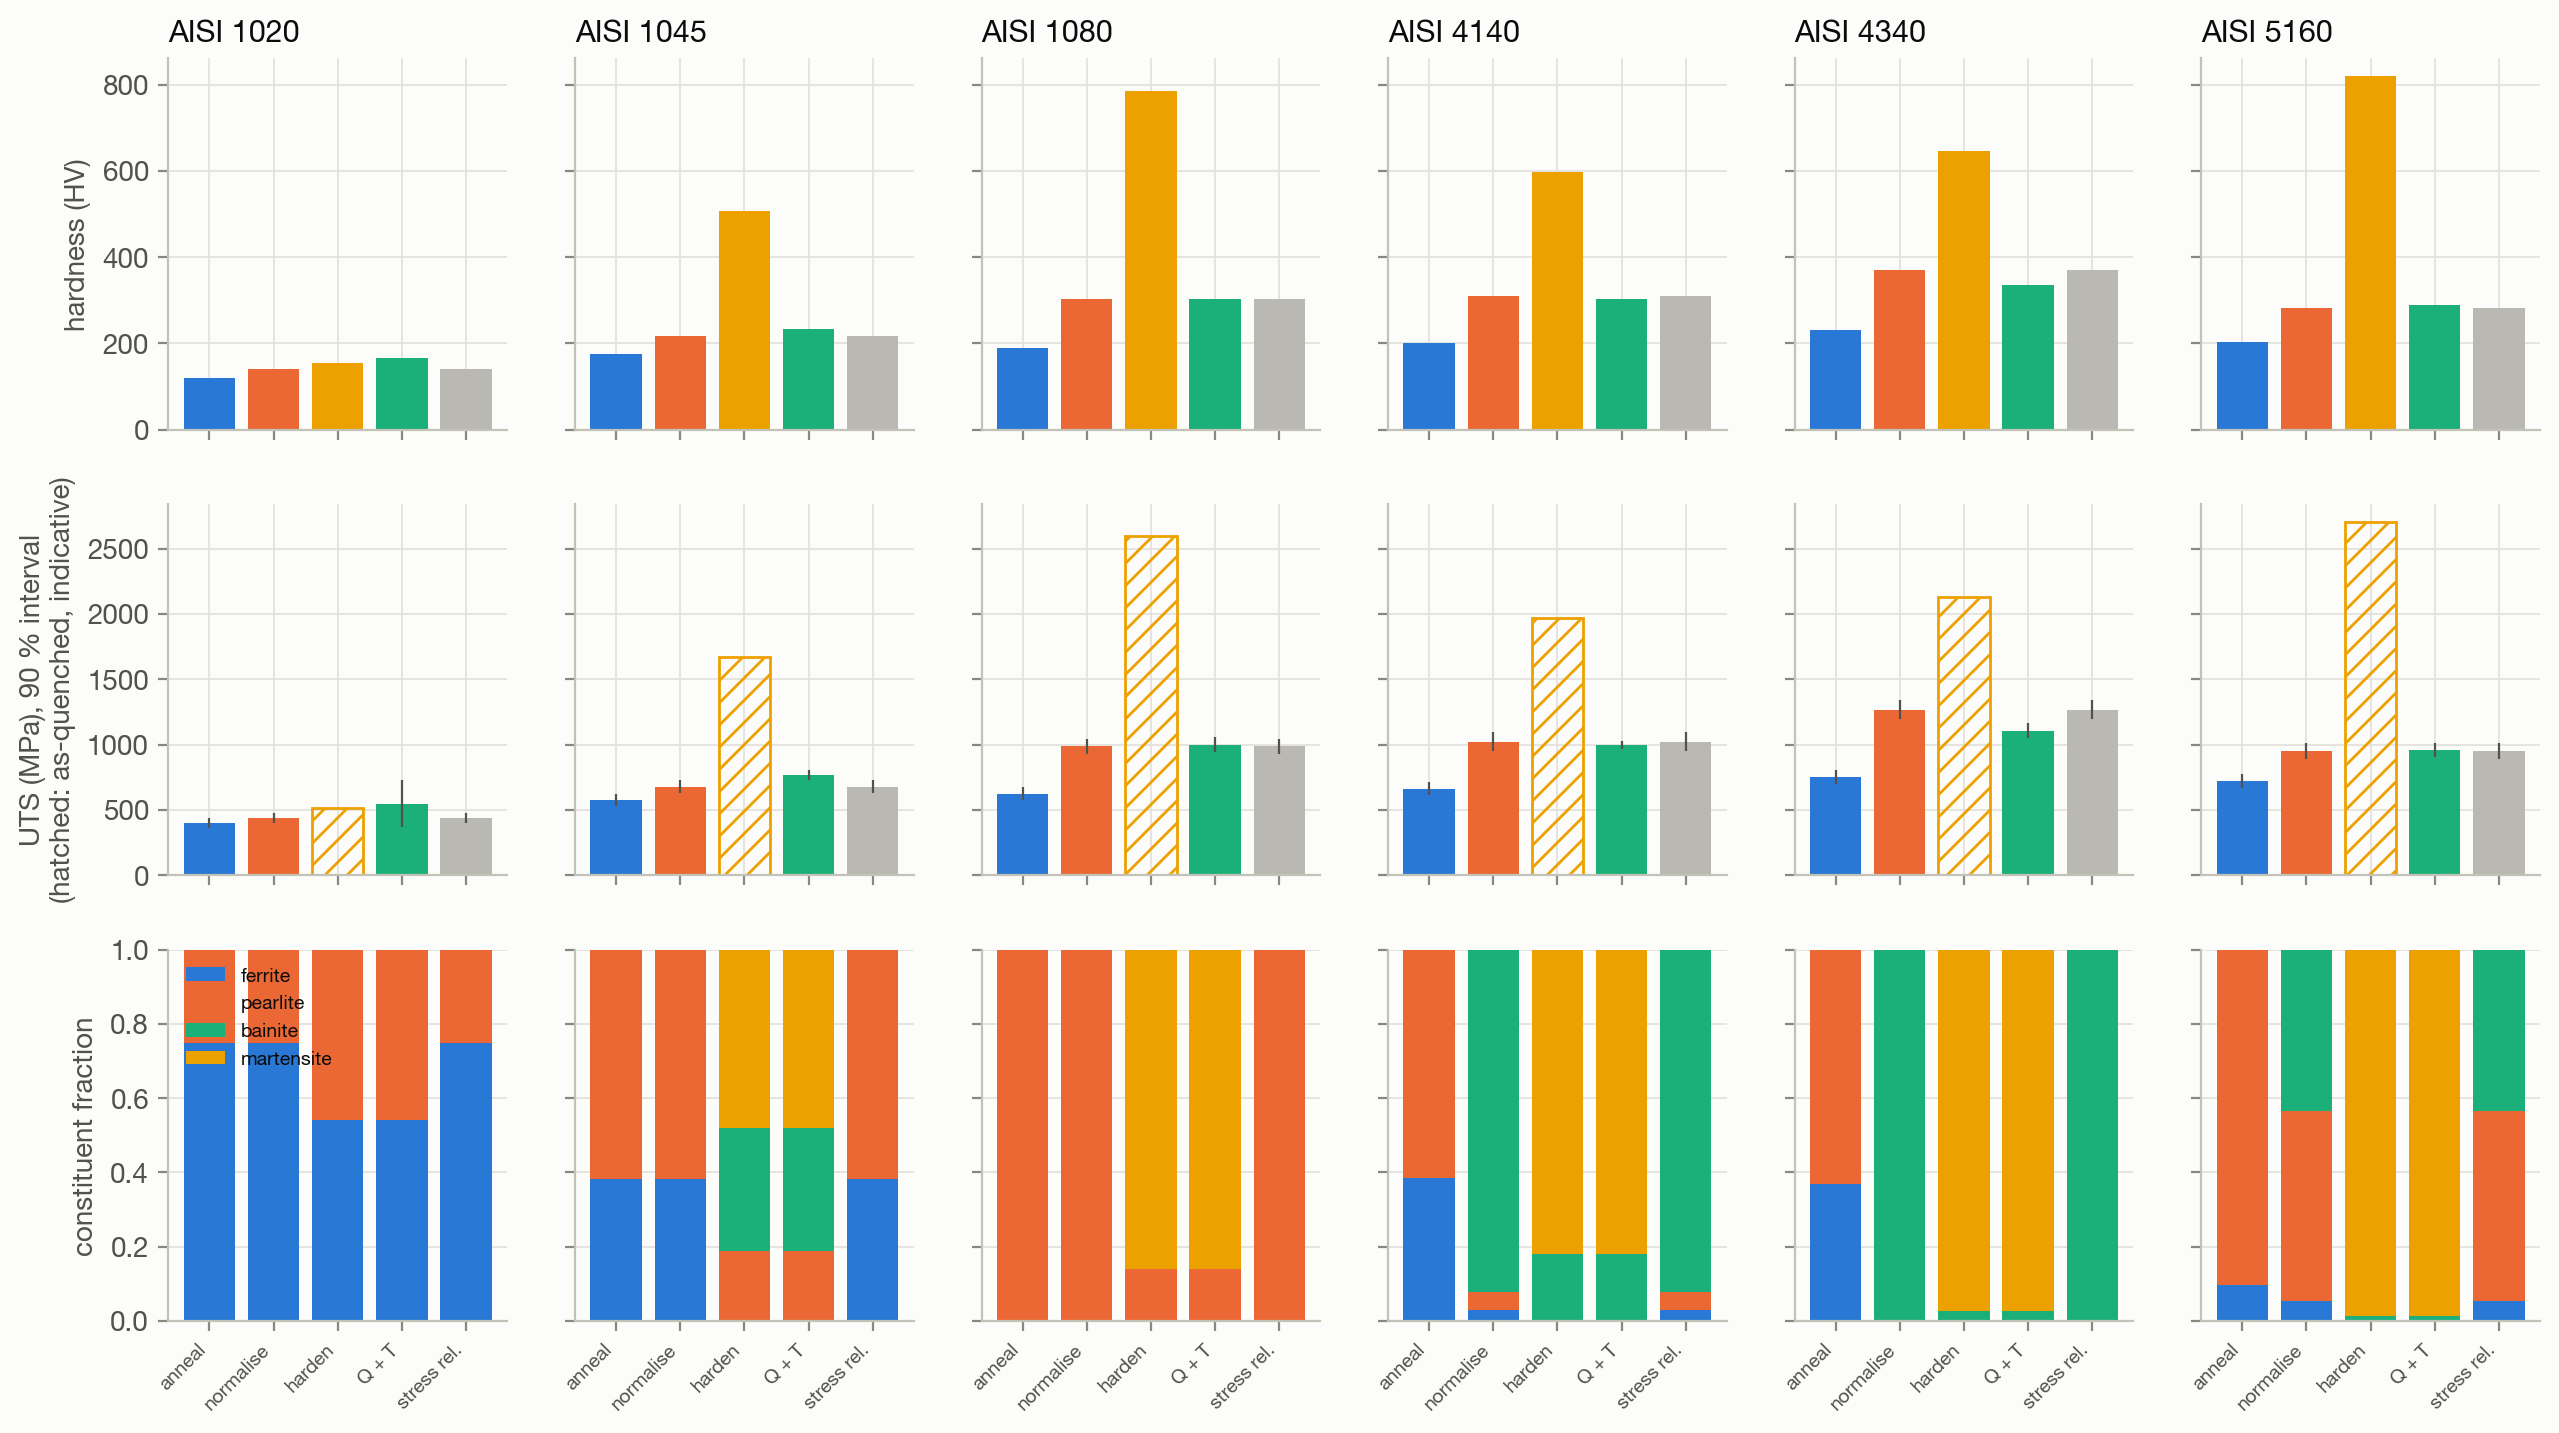

In [12]:
fig("fig36_five_heat_treatments", 1000)

## A live example: an EN19-type (42CrMo4) bar of 30 mm
The same call works for any composition; the tool flags microalloyed, TMCP-type and boron steels.

In [13]:
from steelml.predictor import SteelPredictor
sp = SteelPredictor.load()
comp = {"C": 0.42, "Mn": 0.75, "Si": 0.25, "Cr": 1.05, "Mo": 0.22, "Ni": 0.10}
out = sp.compare_treatments(comp, section_mm=30, temper_T=600)
out[["treatment", "medium", "microstructure", "UTS_MPa_pred", "UTS_MPa_lo90", "UTS_MPa_hi90", "YS_MPa_pred", "El_pct_pred", "HV", "notes"]].round(0)

,treatment,medium,microstructure,UTS_MPa_pred,UTS_MPa_lo90,UTS_MPa_hi90,YS_MPa_pred,El_pct_pred,HV,notes
0,anneal,furnace,coarse pearlite 64% + ferrite 36%,671,619,723,413,24,203,
1,normalise,still air,bainite 85% + fine pearlite 10% + ferrite 5%,988,884,1.09e+03,612,17,295,
2,harden,oil,martensite 78% + bainite 22%,NaN,NaN,NaN,NaN,NaN,598,
3,quench_temper,oil,tempered martensite 78% + tempered bainite 22%,1.01e+03,897,1.12e+03,906,19,306,
4,stress_relieve,still air,unchanged: bainite 85% + fine pearlite 10% + f...,988,884,1.09e+03,612,17,295,


## Stress relieving and precipitation

In [14]:
pd.read_csv(R / "s09_stress_relief_after_temper.csv").round(0)

,grade,temper,sr_T_C,sr_h,P_before,P_after,UTS_after_MPa,subcritical,residual_stress_bound_MPa
0,4140,600 C / 1 h,500,1,1.75e+04,1.75e+04,998,True,707
1,4140,600 C / 1 h,550,1,1.75e+04,1.75e+04,998,True,566
2,4140,600 C / 1 h,575,1,1.75e+04,1.75e+04,991,True,492
3,4140,600 C / 1 h,600,1,1.75e+04,1.77e+04,977,True,415
4,4140,600 C / 1 h,625,1,1.75e+04,1.81e+04,951,True,349
5,4140,600 C / 1 h,650,1,1.75e+04,1.85e+04,916,True,283


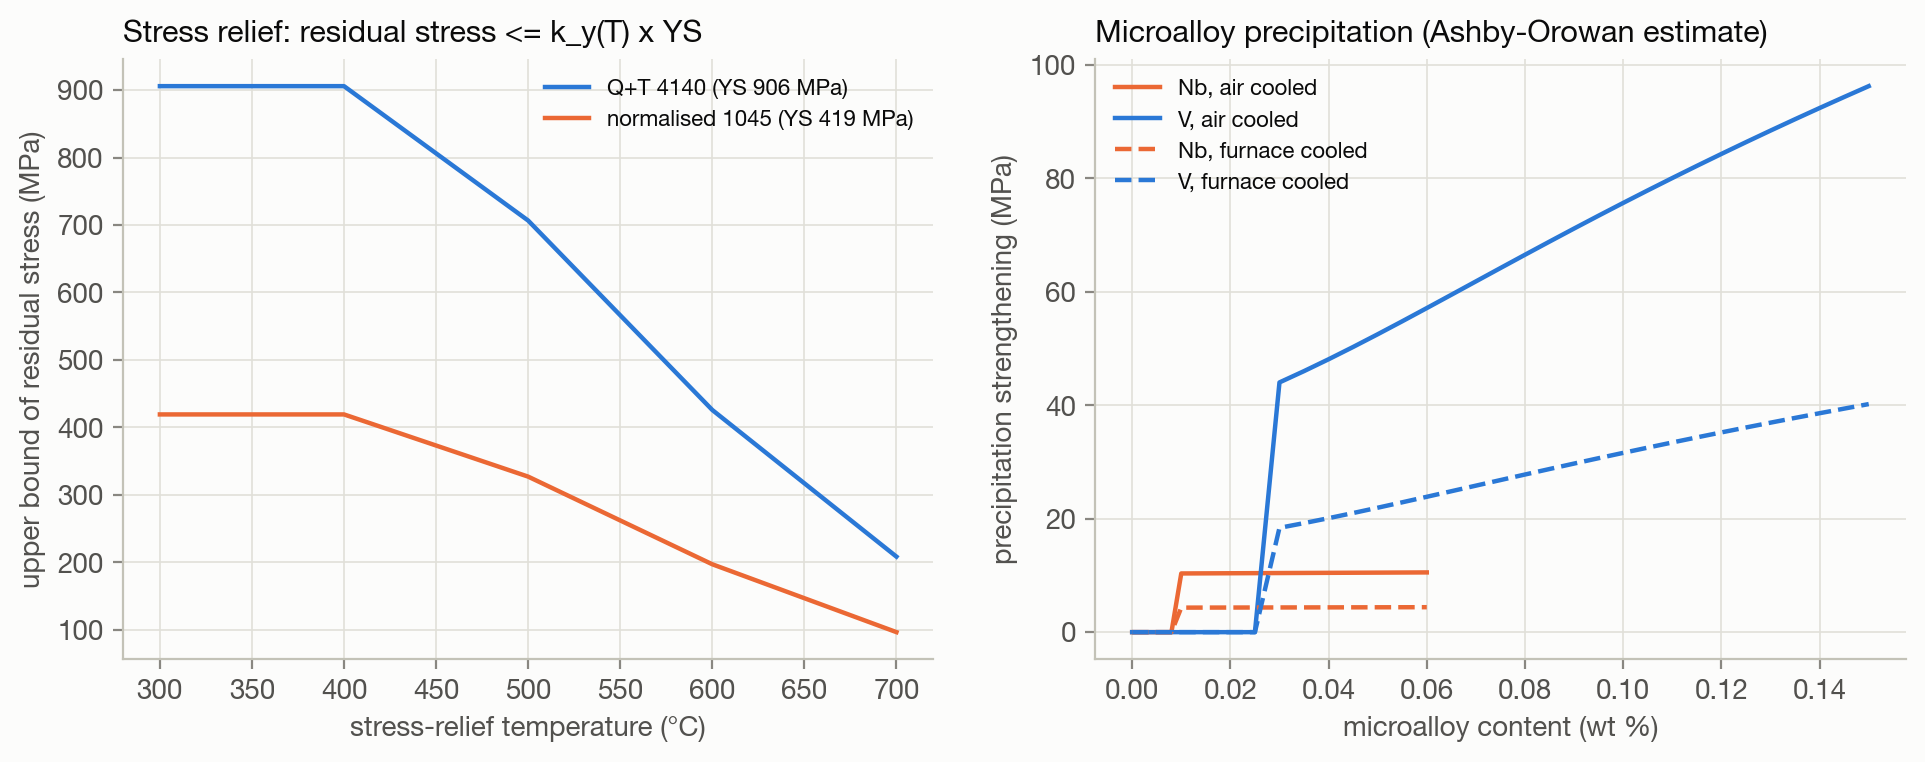

In [15]:
fig("fig37_stress_relief_and_precipitation", 1000)